<a href="https://colab.research.google.com/github/tiffanysoe1/Reinforcement-Learning/blob/main/ReinforcementLearning_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reinforcement Learning Tutorial

---

Part 1: Basic Environment Interaction with a random Agent in CartPole-V1

Part 2: Training, Visualizing, and evaluating a tabular Q-learning agent on Blackjack-v1

Part 3: Designing, Registering, Testing and wrapping a custom 2D GridWorld Environment

# Part 1: CartPole Basics
1.1 Play a Full Game with Random Moves

1.2 Try a Single Move Step-by-Step

# Part 2: Teaching an AI to Play Blackjack
2.1 Define Q-Learning Agent

2.2 Configure Hyperparameters & Training Loop

2.3 Visualize Training Progress

2.4 Evaluate AI

# Part 3: Building Your Own GridWorld Game
3.1 Define GridWorldEnv class & core methods

3.2 Register, Customize & Vectorize the Environment

3.3 Validate & Manually Test Step Transitions

3.4 Apply Observation Wrappers (Modify Environment without changing core code)

3.5 Extra Features: Parameterized Rewards

In [ ]:
import gymnasium as gym

In [ ]:
env = gym.make('CartPole-v1', render_mode='human')
observation, info = env.reset() #reset environment to start a new episode
#observation is what the agent can see - cart position, velocity, pole angle
#info: extra debugging information (not needed for learning)
print(f"Starting Observation: {observation}")
total_reward = 0
episode_over = False
while not episode_over:
  action = env.action_space.sample() # choose random action for now
  observation, reward, terminated, truncated, info = env.step(action) #take action
  total_reward+=total_reward
  episode_over = terminated or truncated
print(f"Total Reward: {total_reward}")
env.close()



/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Starting Observation: [-0.01713827  0.03967479  0.0111271  -0.02268295]
Total Reward: 0


In [ ]:
#dont forget to reset
env = gym.make("CartPole-v1")
obs, info = env.reset()
action = env.action_space.sample()
obs, reward, terminated, truncated, info = env.step(action)


In [ ]:
# Create BlackJack Q-Learning Program
from collections import defaultdict
import gymnasium as gym
import numpy as np


class BlackjackAgent:
    def __init__(
        self,
        env: gym.Env,
        learning_rate: float,
        initial_epsilon: float,
        epsilon_decay: float,
        final_epsilon: float,
        discount_factor: float = 0.95,
    ):
        """Initialize a Q-Learning Agent
        Args:
            env: the training environment
            learning_rate
            initial_epsilon (starting exploration rate)
            epsilon_decay
            final_epsilon: minimum exploration rate
            discount factor: how much to value future rewards
        """
        self.env = env
        self.q_values = defaultdict(lambda: np.zeros(env.action_space.n))
        self.lr = learning_rate
        self.discount_factor = discount_factor
        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon

        self.training_error = []

    def get_action(self, obs: tuple[int, int, bool]) -> int:
        """Choose an action using the epsilon greedy strategy.
        Returns:
            action(0) stand or 1(hit)
        """
        # with probability epsilon: explore (random action)
        if np.random.random() < self.epsilon:
            return self.env.action_space.sample()
        else:
            return int(np.argmax(self.q_values[obs]))

    def update(
        self,
        obs: tuple[int, int, bool],
        action: int,
        reward: float,
        terminated: bool,
        next_obs: tuple[int, int, bool],
    ):
        """Update Q-value based on experience. This is the heart of Q-learning: learn from (state, action, reward, next_state)"""
        # What's the best we could from the next state?
        # (Zero if episode is terminated - no future rewards possible)
        future_q_value = (not terminated) * np.max(self.q_values[next_obs])
        target = reward + self.discount_factor * future_q_value
        temporal_difference = target - self.q_values[obs][action]
        self.q_values[obs][action] = (
            self.q_values[obs][action] + self.lr * temporal_difference
        )
        self.training_error.append(temporal_difference)

    def decay_epsilon(self):
        "Reduce exploration rate over time"
        self.epsilon = max(self.final_epsilon, self.epsilon * self.epsilon_decay)

In [ ]:
#Training Hyperparameters
learning_rate = 0.01
n_episodes = 100_000
start_epsilon = 1.0
epsilon_decay = start_epsilon/ (n_episodes/2)
final_epsilon = 0.1

#create environment
env = gym.make("Blackjack-v1", sab=False)
env = gym.wrappers.RecordEpisodeStatistics(env)
agent = BlackjackAgent(
    env=env,
    learning_rate=learning_rate,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon,
)



In [ ]:
#Training Loop
from tqdm import tqdm #progress bar
for episode in tqdm(range(n_episodes)):
  #Start a New Hand
  obs, info = env.reset()
  done = False
  while not done:
    action = agent.get_action(obs) #what to do
    next_obs, reward, terminated, truncated, info = env.step(action) #take action
    #learn from this experience
    agent.update(obs, action, reward, terminated, next_obs)
    #move to next state
    obs = next_obs
    done = terminated or truncated

  #reduce exploration rate (agent becomes less random over time)
  agent.decay_epsilon()


100%|██████████| 100000/100000 [00:19<00:00, 5059.85it/s]


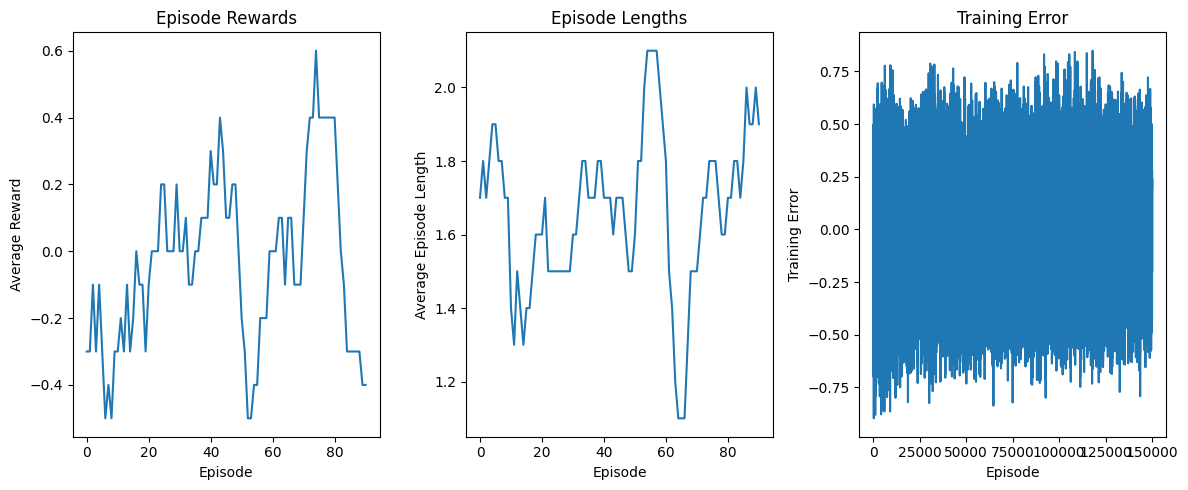

In [ ]:
from matplotlib import pyplot as plt
import numpy as np
def get_moving_avgs(arr, window, convolution_mode):
    return (
        np.convolve(
            np.array(arr).flatten(),
            np.ones(window),
            mode=convolution_mode,
        )
        / window
    )


rolling_length = 10
fig, axs = plt.subplots(ncols=3, figsize=(12, 5))

axs[0].set_title("Episode Rewards")
reward_moving_avgs = get_moving_avgs(
    agent.env.return_queue,
    window=rolling_length,
    convolution_mode="valid",
)
axs[0].plot(range(len(reward_moving_avgs)), reward_moving_avgs)
axs[0].set_ylabel("Average Reward")
axs[0].set_xlabel("Episode")

axs[1].set_title("Episode Lengths")
length_moving_avgs = get_moving_avgs(
    agent.env.length_queue,
    window=rolling_length,
    convolution_mode="valid",
)
axs[1].plot(range(len(length_moving_avgs)), length_moving_avgs)
axs[1].set_ylabel("Average Episode Length")
axs[1].set_xlabel("Episode")

axs[2].set_title("Training Error")
training_error_moving_avgs = get_moving_avgs(
    agent.training_error,
    window=rolling_length,
    convolution_mode="same",
)
axs[2].plot(range(len(training_error_moving_avgs)), training_error_moving_avgs)
axs[2].set_ylabel("Training Error")
axs[2].set_xlabel("Episode")

plt.tight_layout()
plt.show()


In [ ]:
#test trained agent
def test_agent(agent, env, num_episodes=1000):
  total_rewards = []

  #temporarily disable epsilon for testing
  old_epsilon = agent.epsilon
  agent.epsilon = 0.0 #pure exploitation

  for _ in range(num_episodes):
    obs, info = env.reset()
    done = False
    total_reward = 0

    while not done:
      action = agent.get_action(obs)
      obs, reward, terminated, truncated, info = env.step(action)
      total_reward += reward
      done = terminated or truncated
    total_rewards.append(total_reward)

  #restore original epsilon
  agent.epsilon = old_epsilon

  win_rate = np.mean(np.array(total_rewards)>0)
  average_reward = np.mean(total_rewards)

  print(f"Test Results over: {num_episodes} episodes")
  print(f"Win Rate: {win_rate:.1%}")
  print(f"Average Reward: {average_reward:.3f}")
  print(f"Standard Deviation: {np.std(total_rewards):.3f}")

test_agent(agent,env)


Test Results over: 1000 episodes
Win Rate: 41.7%
Average Reward: -0.053
Standard Deviation: 0.940


In [ ]:
#Creating Custom Environment

from typing import Optional
import numpy as np
import gymnasium as gym

class GridWorldEnv(gym.Env):
  def __init__(self, size: int=5):
    self.size = size
    self._agent_location = np.array([-1, -1], dtype=np.int32)
    self._target_location = np.array([-1, -1], dtype=np.int32)

    #Define what the agent can observe
    #Dict space gives us structured, human-readable observations
    self.observation_space = gym.spaces.Dict(
        {
            "agent": gym.spaces.Box(0, size-1, shape=(2,), dtype=int),
            "target": gym.spaces.Box(0, size-1, shape=(2,), dtype=int),
        }
    )
    self.action_space = gym.spaces.Discrete(4)

    #map action numbers to actual movements on the grid
    self._action_to_direction = {
        0: np.array([0, 1]),
        1: np.array([-1, 0]),
        2: np.array([0, -1]),
        3: np.array([1, 0]),
    }

In [ ]:
#Converts Internal State to Observation Format
def _get_obs(self):
  """Returns:
      dict: Observation with agent and target positions
  """
  return {
      "agent": self._agent_location,
      "target": self._target_location,
  }


In [ ]:
from typing import Optional

#Reset ensure agent and target is not on the same location
""" Starts a new episode.
    Seed: Random Seed for reproducible episodes
    Options: Additional Configuration(unused in the example)
    Returns: Tuple (Observation, Info) for the initial state
"""


def reset(self, seed: Optional[int] = None, options: Optional[dict] = None):
        # IMPORTANT: Must call this first to seed the random number generator
        super().reset(seed=seed)

        # Randomly place the agent anywhere on the grid
        self._agent_location = self.np_random.integers(0, self.size, size=2, dtype=int)

        # Randomly place target, ensuring it's different from agent position
        self._target_location = self._agent_location
        while np.array_equal(self._target_location, self._agent_location):
            self._target_location = self.np_random.integers(
                0, self.size, size=2, dtype=int
            )

        observation = self._get_obs()
        info = self._get_info()

        return observation, info

In [ ]:
#Register the environment so we can create it with gym.make()
gym.register(
    id="gymnasium_env/GridWorld-v0",
    entry_point=GridWorldEnv,
    max_episode_steps=300 #prevent infinite episodes
)

In [ ]:
import gymnasium as gym
env=gym.make("gymnasium_env/GridWorld-v0")

#customize environment parameters
env = gym.make("gymnasium_env/GridWorld-v0", size=10)
env.unwrapped.size

#create multiple environments for parallel training
vec_env = gym.vector.SyncVectorEnv([lambda: env for _ in range(4)])


In [ ]:
#Debugging Environment
from gymnasium.utils.env_checker import check_env
try:
  check_env(env)
  print("Environment passes all checks!")
except Exception as e:
  Print(f"Environment has problem {e}")

In [ ]:
#Manual Testing with Known Actions
env = gym.make("gymnasium_env/GridWorld-v0")
obs, info = env.reset(seed=42)

print(f"Starting Position - Agent: {obs['agent']}, Target: {obs['target']}")

actions= [0,1,2,3]
for action in actions:
  old_pos = obs['agent'].copy()
  obs, reward, terminated, truncated, info = env.step(action)
  new_pos = obs['agent']
  print(f"Action {action}: Agent moved from {old_pos} to {new_pos}, reward={reward}")



In [ ]:
#Using Wrappers: Modify your environment behaviours without changing core implementation.
from gymnasium.wrappers import FlattenObservation
#original observation is a dict, change it to array
env = gym.make("gymnasium_env/GridWorld-v0")
env.observation_space

obs, info = env.reset()
obs


In [ ]:
wrapped_env =FlattenObservation(env) #flatten to single array
wrapped_env.observation_space
obs,info = wrapped_env.reset()

In [ ]:
#Advanced Environment Features
def render(self):
  if self.render_mode == "human":
    #Print Simple ASCII representation
    for y in range(self.size -1, -1, -1):
      row = ""
      for x in range(self.size):
        if np.array_equal([x,y], self._agent_location):
          row += "A"
        elif np.array_equal([x,y], self._target.location):
          row += "T"
        else:
          row += "."
      print(row)
    print()

In [ ]:
#Parameterized Environments
def _init_(self, size: int = 5, reward_scale: float=1.0, step_penalty: float= 0.0):
    self.size = size
    self.reward_scale = reward_scale
    self.step_penalty = step_penalty
def step(self, action):
  #Movement Logic
  #Flexible Reward Calculation
  if terminated:
    reward = self.reward_scale
  else:
    reward = -self.step_penalty